# Counter-Based Taxi Problem Visualization

This notebook demonstrates the counter-based taxi problem implementation where:
- State space: (row, column, counter) where counter ∈ {0, 1, 2}
- Counter increments: 0→1 at stop1, 1→2 at stop2 (sequential dependency)
- Goal is only reachable when counter=2 (both stops completed)
- Uses the same backend as the task implementation in `taxi_problem.py`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from value_iteration.task.taxi_problem import pos_to_state, state_to_pos, make_gridworld_taxi
from value_iteration.utils.plot_utils.taxi_visualization import TaxiVisualization, create_taxi_visualization


## Configuration

**Change these coordinates to move the elements around the gridworld:**

In [2]:
# Grid configuration using counter-based system
GRID_SIZE = 10
TOTAL_STATES = 3 * GRID_SIZE * GRID_SIZE  # Three layers: counter=0,1,2

# Positions (row, column) - coordinates are (0,0) to (9,9)
AGENT_POS = (0, 0)          # Starting position of taxi
STOP1_POS = (4, 5)          # First stop (counter: 0→1)
STOP2_POS = (7, 2)          # Second stop (counter: 1→2)  
GOAL_POS = (9, 9)           # Final goal (accessible when counter=2)

print(f"Configuration:")
print(f"Grid size: {GRID_SIZE}x{GRID_SIZE}")
print(f"Total states: {TOTAL_STATES}")
print(f"Agent start: {AGENT_POS}")
print(f"Stop 1: {STOP1_POS}")
print(f"Stop 2: {STOP2_POS}")
print(f"Goal: {GOAL_POS}")

# Key state indices using the counter-based system
agent_state = pos_to_state(AGENT_POS[0], AGENT_POS[1], 0, GRID_SIZE)
stop1_state_c0 = pos_to_state(STOP1_POS[0], STOP1_POS[1], 0, GRID_SIZE)
stop1_state_c1 = pos_to_state(STOP1_POS[0], STOP1_POS[1], 1, GRID_SIZE)
stop2_state_c1 = pos_to_state(STOP2_POS[0], STOP2_POS[1], 1, GRID_SIZE)
stop2_state_c2 = pos_to_state(STOP2_POS[0], STOP2_POS[1], 2, GRID_SIZE)
goal_state = pos_to_state(GOAL_POS[0], GOAL_POS[1], 2, GRID_SIZE)

print(f"\nKey state indices:")
print(f"Agent (0,0,c=0): {agent_state}")
print(f"Stop1 (4,5,c=0): {stop1_state_c0}")
print(f"Stop1 (4,5,c=1): {stop1_state_c1}")
print(f"Stop2 (7,2,c=1): {stop2_state_c1}")
print(f"Stop2 (7,2,c=2): {stop2_state_c2}")
print(f"Goal (9,9,c=2): {goal_state}")

Configuration:
Grid size: 10x10
Total states: 300
Agent start: (0, 0)
Stop 1: (4, 5)
Stop 2: (7, 2)
Goal: (9, 9)

Key state indices:
Agent (0,0,c=0): 0
Stop1 (4,5,c=0): 45
Stop1 (4,5,c=1): 145
Stop2 (7,2,c=1): 172
Stop2 (7,2,c=2): 272
Goal (9,9,c=2): 299


## Create Counter-Based Taxi Problem

This uses the same backend implementation as defined in `taxi_problem.py`:

In [3]:
# Create the taxi visualization instance
taxi_viz = create_taxi_visualization(
    grid_size=GRID_SIZE,
    agent_pos=AGENT_POS,
    stop1_pos=STOP1_POS,
    stop2_pos=STOP2_POS,
    goal_pos=GOAL_POS
)

# Analyze the problem structure
analysis = taxi_viz.analyze_connectivity()

=== Counter-Based Taxi Problem Analysis ===
Total states: 300
Grid size: 10x10
Number of layers (counter values): 3
Total connections: 1186
Average connections per state: 3.95
Matrix density: 1.3178%

Key States:
Agent starting state (0,0,counter=0): 0
Stop 1 at counter=0: 45
Stop 1 at counter=1: 145
Stop 2 at counter=1: 172
Stop 2 at counter=2: 272
Goal at counter=2: 299

Goal State Analysis:
Goal state 299 is absorbing: True
Goal connections: [299]


## Gridworld Visualization

Shows the taxi problem with sequential stop dependencies:

/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE

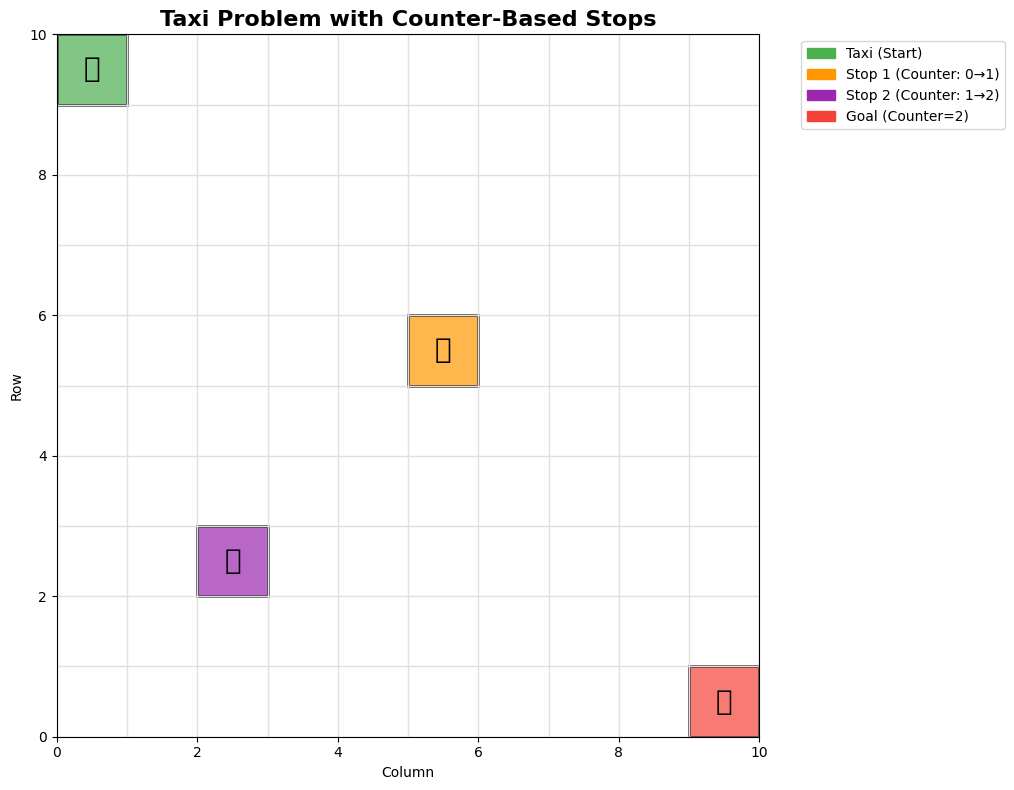


Sequential Dependencies:
🤖 (Start, counter=0) → ⭐ (Stop 1, counter=1) → 💎 (Stop 2, counter=2) → 🎯 (Goal)

Counter-based rules:
- Counter starts at 0
- Visiting Stop 1 while counter=0 increments to counter=1
- Visiting Stop 2 while counter=1 increments to counter=2
- Goal is only reachable when counter=2


In [4]:
# Create gridworld visualization
fig, ax = taxi_viz.visualize_gridworld(figsize=(10, 8))
plt.show()

print("\nSequential Dependencies:")
print("🤖 (Start, counter=0) → ⭐ (Stop 1, counter=1) → 💎 (Stop 2, counter=2) → 🎯 (Goal)")
print("\nCounter-based rules:")
print("- Counter starts at 0")
print("- Visiting Stop 1 while counter=0 increments to counter=1")
print("- Visiting Stop 2 while counter=1 increments to counter=2")
print("- Goal is only reachable when counter=2")

## Combined Visualization

Shows both the gridworld and the underlying state transition graph:

/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:317: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:317: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:317: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:317: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


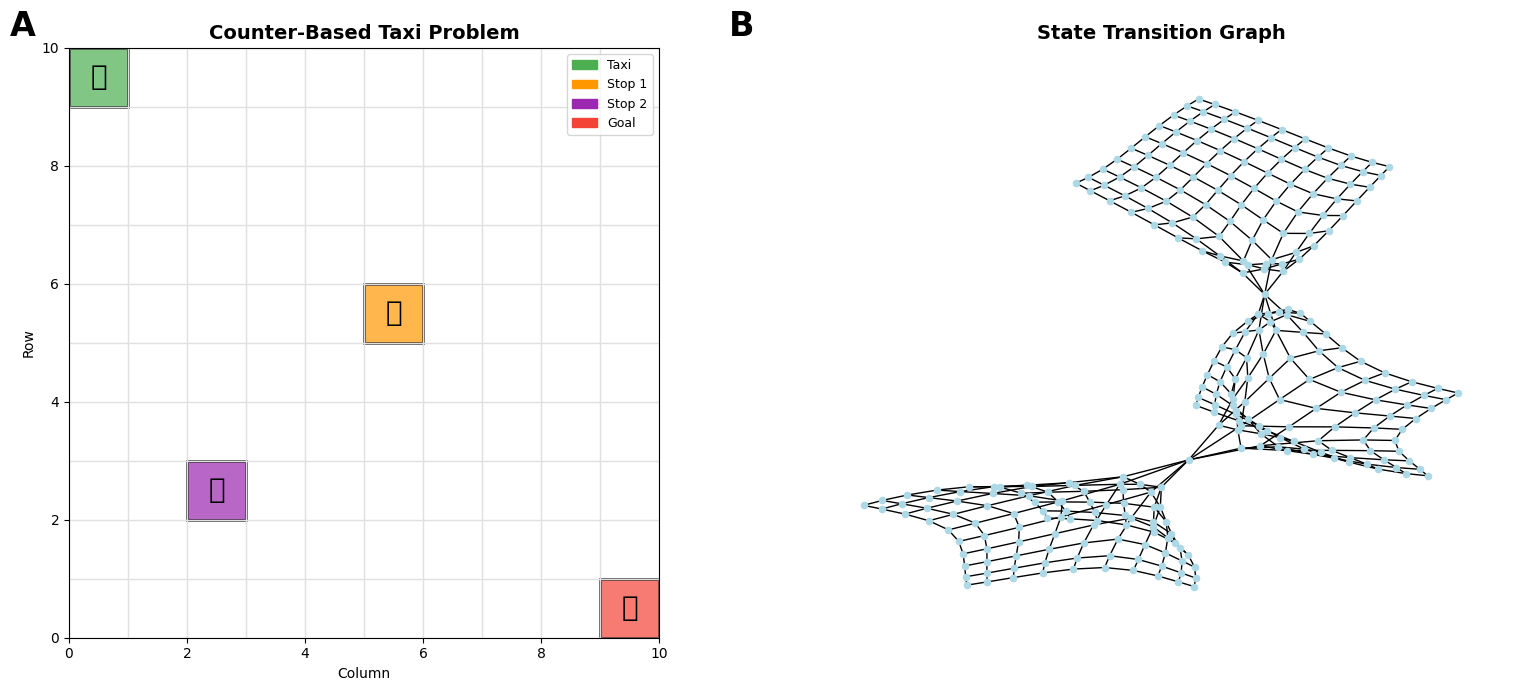

In [5]:
# Create combined visualization (self-transitions hidden by default for cleaner view)
fig, (ax1, ax2) = taxi_viz.visualize_combined_view(figsize=(16, 7), show_self_transitions=False)
plt.show()

## Self-Transition Control

The visualization supports masking self-transitions for cleaner graph views. Self-transitions occur due to:
1. **Border Effects**: When trying to move out of bounds, agent stays put
2. **Slip Probability**: Stochastic actions can result in staying in the same state
3. **Goal Absorption**: Goal state always transitions to itself

Transition Matrix Comparison:


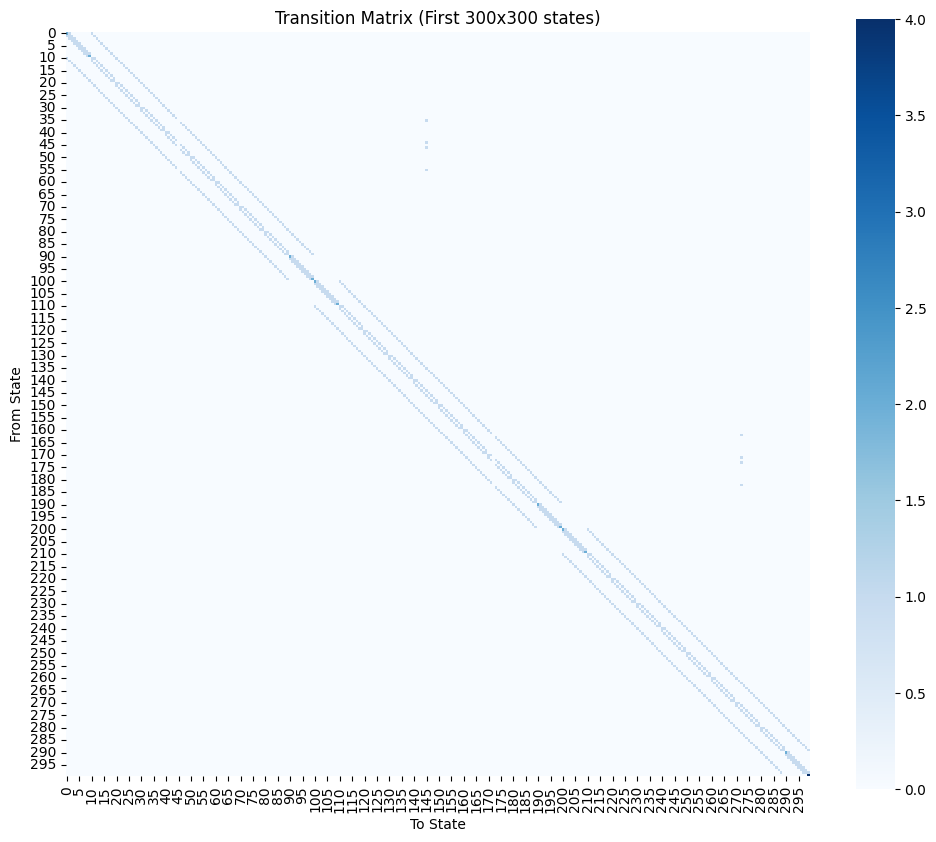

In [6]:
# Also update the transition matrix visualization
print("Transition Matrix Comparison:")

# Show matrix without self-transitions for cleaner view
taxi_viz.visualize_adjacency_matrix(max_states_to_show=300, show_self_transitions=True)

## State Space Structure

Demonstrate the counter-based state encoding:

In [7]:
# Demonstrate state encoding and decoding
print("State Space Structure (Counter-Based):")
print("="*50)

# Show layer structure
print(f"Layer 0 (counter=0): States 0 to {GRID_SIZE*GRID_SIZE-1}")
print(f"Layer 1 (counter=1): States {GRID_SIZE*GRID_SIZE} to {2*GRID_SIZE*GRID_SIZE-1}")
print(f"Layer 2 (counter=2): States {2*GRID_SIZE*GRID_SIZE} to {3*GRID_SIZE*GRID_SIZE-1}")

print("\nExample state conversions:")
test_positions = [(0,0,0), (4,5,1), (7,2,2), (9,9,2)]
for row, col, counter in test_positions:
    state = pos_to_state(row, col, counter, GRID_SIZE)
    decoded = state_to_pos(state, GRID_SIZE)
    print(f"  ({row},{col},c={counter}) → state {state} → {decoded}")

print("\nCritical transitions:")
print(f"  Stop 1 visit: counter 0→1 (states {stop1_state_c0}→{stop1_state_c1})")
print(f"  Stop 2 visit: counter 1→2 (states {stop2_state_c1}→{stop2_state_c2})")
print(f"  Goal achievable only at state {goal_state} (counter=2)")

State Space Structure (Counter-Based):
Layer 0 (counter=0): States 0 to 99
Layer 1 (counter=1): States 100 to 199
Layer 2 (counter=2): States 200 to 299

Example state conversions:
  (0,0,c=0) → state 0 → (0, 0, 0)
  (4,5,c=1) → state 145 → (4, 5, 1)
  (7,2,c=2) → state 272 → (7, 2, 2)
  (9,9,c=2) → state 299 → (9, 9, 2)

Critical transitions:
  Stop 1 visit: counter 0→1 (states 45→145)
  Stop 2 visit: counter 1→2 (states 172→272)
  Goal achievable only at state 299 (counter=2)


## Test Different Configurations

Show how easy it is to reconfigure the problem:

/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 128142 (\N{GEM STONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/src/value_iteration/utils/plot_utils/taxi_visualization.py:176: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/nicholasfranklin/Projects/ValueIteration/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE

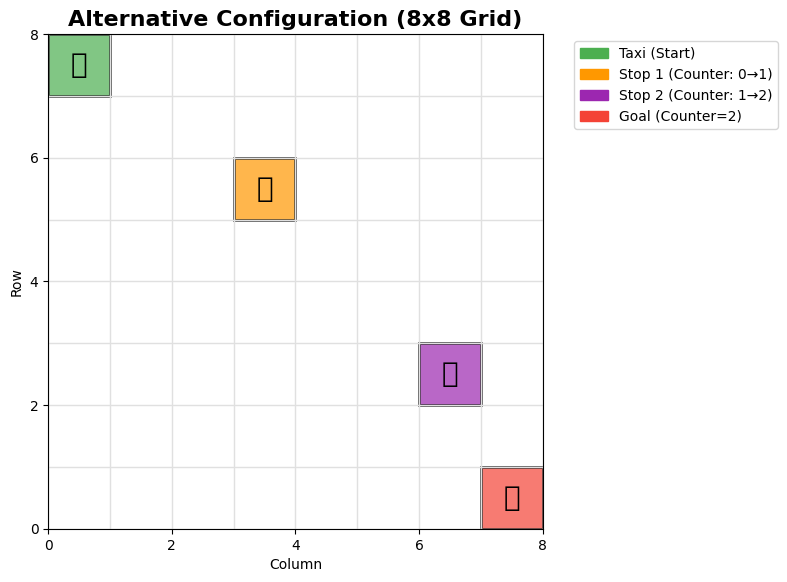

=== Counter-Based Taxi Problem Analysis ===
Total states: 192
Grid size: 8x8
Number of layers (counter values): 3
Total connections: 754
Average connections per state: 3.93
Matrix density: 2.0454%

Key States:
Agent starting state (0,0,counter=0): 0
Stop 1 at counter=0: 19
Stop 1 at counter=1: 83
Stop 2 at counter=1: 110
Stop 2 at counter=2: 174
Goal at counter=2: 191

Goal State Analysis:
Goal state 191 is absorbing: True
Goal connections: [191]

Comparison of configurations:
Original 10x10: 300 states, 1186 connections
Alternative 8x8: 192 states, 754 connections


In [8]:
# Create alternative configuration
alt_taxi_viz = create_taxi_visualization(
    grid_size=8,
    agent_pos=(0, 0),
    stop1_pos=(2, 3),
    stop2_pos=(5, 6),
    goal_pos=(7, 7)
)

# Visualize alternative configuration
fig, ax = alt_taxi_viz.visualize_gridworld(figsize=(8, 8))
plt.title('Alternative Configuration (8x8 Grid)', fontsize=16, fontweight='bold')
plt.show()

# Analyze alternative configuration
alt_analysis = alt_taxi_viz.analyze_connectivity()

print("\nComparison of configurations:")
print(f"Original 10x10: {analysis['total_states']} states, {analysis['total_connections']} connections")
print(f"Alternative 8x8: {alt_analysis['total_states']} states, {alt_analysis['total_connections']} connections")

## Verify Backend Consistency

Ensure our visualization uses the exact same implementation as the task:

In [9]:
# Test that we're using the same backend
direct_transitions, direct_rewards, direct_policy = make_gridworld_taxi(
    grid_size=GRID_SIZE,
    agent_pos=AGENT_POS,
    stop1_pos=STOP1_POS,
    stop2_pos=STOP2_POS,
    goal_pos=GOAL_POS
)

# Verify shapes match
print("Backend Consistency Check:")
print(f"Direct call - Transitions shape: {len(direct_transitions)} actions x {direct_transitions[0].shape}")
print(f"Direct call - Rewards shape: {direct_rewards.shape}")
print(f"Visualization - Transitions shape: {len(taxi_viz.transitions)} actions x {taxi_viz.transitions[0].shape}")
print(f"Visualization - Rewards shape: {taxi_viz.rewards.shape}")

# Check that goal state has correct reward
goal_reward_direct = direct_rewards[goal_state]
goal_reward_viz = taxi_viz.rewards[goal_state]
print(f"\nGoal state reward consistency:")
print(f"Direct call: {goal_reward_direct}")
print(f"Visualization: {goal_reward_viz}")
print(f"Match: {np.isclose(goal_reward_direct, goal_reward_viz)}")

print("\n✅ Backend consistency verified - both use the same counter-based implementation!")

Backend Consistency Check:
Direct call - Transitions shape: 4 actions x (300, 300)
Direct call - Rewards shape: (300,)
Visualization - Transitions shape: 4 actions x (300, 300)
Visualization - Rewards shape: (300,)

Goal state reward consistency:
Direct call: 1.0
Visualization: 1.0
Match: True

✅ Backend consistency verified - both use the same counter-based implementation!
